Step 1 — Import Required Libraries

In [2]:
# Task 8: Generative AI and Deep Learning Model Optimization

import tensorflow as tf
from tensorflow import keras

import numpy as np
import matplotlib.pyplot as plt

import os
import time

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.20.0


Step 2 — Load the MNIST Dataset

In [3]:
# Load MNIST dataset

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


Step 3 — Preprocess the MNIST Images

In [4]:
# Preprocess MNIST images

x_train = x_train.astype("float32")

# Normalize pixel values to the range [-1, 1]
x_train = (x_train - 127.5) / 127.5

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)

print("Preprocessed shape:", x_train.shape)
print("Minimum value:", x_train.min())
print("Maximum value:", x_train.max())

Preprocessed shape: (60000, 28, 28, 1)
Minimum value: -1.0
Maximum value: 1.0


Step 4 — Create the Training Dataset

In [5]:
# Create TensorFlow dataset

BATCH_SIZE = 128
BUFFER_SIZE = 60000

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)

train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)

print("Batch size:", BATCH_SIZE)
print("Dataset prepared successfully!")

Batch size: 128
Dataset prepared successfully!


Step 5 — Build the Generator Network

In [6]:
# Build the Generator network

def build_generator():
    model = keras.Sequential(name="Generator")

    # Input: random noise vector
    model.add(keras.layers.Dense(7 * 7 * 128, use_bias=False, input_shape=(100,)))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.LeakyReLU())

    # Reshape into feature maps
    model.add(keras.layers.Reshape((7, 7, 128)))

    # Upsampling: 7x7 -> 14x14
    model.add(keras.layers.Conv2DTranspose(
        64, kernel_size=5, strides=2,
        padding="same", use_bias=False
    ))
    model.add(keras.layers.BatchNormalization())
    model.add(keras.layers.LeakyReLU())

    # Upsampling: 14x14 -> 28x28
    model.add(keras.layers.Conv2DTranspose(
        1, kernel_size=5, strides=2,
        padding="same", use_bias=False,
        activation="tanh"
    ))

    return model


generator = build_generator()

generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 858,944 (3.28 MB)

 Trainable params: 846,272 (3.23 MB)

 Non-trainable params: 12,672 (49.50 KB)

Step 6 — Build the Discriminator Network

In [7]:
# Build the Discriminator network

def build_discriminator():
    model = keras.Sequential(name="Discriminator")

    # Input image: 28x28x1
    model.add(keras.layers.Conv2D(
        64, kernel_size=5, strides=2,
        padding="same", input_shape=(28, 28, 1)
    ))
    model.add(keras.layers.LeakyReLU())
    model.add(keras.layers.Dropout(0.3))

    model.add(keras.layers.Conv2D(
        128, kernel_size=5, strides=2,
        padding="same"
    ))
    model.add(keras.layers.LeakyReLU())
    model.add(keras.layers.Dropout(0.3))

    # Flatten feature maps
    model.add(keras.layers.Flatten())

    # Output probability
    model.add(keras.layers.Dense(1))

    return model


discriminator = build_discriminator()

discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Step 7 — Test the Generator and Discriminator

In [8]:
# Test the Generator

noise = tf.random.normal([1, 100])

generated_image = generator(noise, training=False)

print("Generated image shape:", generated_image.shape)

Generated image shape: (1, 28, 28, 1)


In [9]:
# Test the Discriminator

decision = discriminator(generated_image, training=False)

print("Discriminator output shape:", decision.shape)
print("Discriminator output:", decision.numpy())

Discriminator output shape: (1, 1)
Discriminator output: [[-0.00070796]]


Step 8 — Define GAN Loss Functions

In [10]:
# Define Binary Cross-Entropy loss

cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)


# Generator loss
def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )


# Discriminator loss
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss


print("Loss functions defined successfully!")

Loss functions defined successfully!


Step 9 — Define Optimizers

In [11]:

# Define optimizers

generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

print("Optimizers created successfully!")

Optimizers created successfully!


Step 10 — Define the GAN Training Step

In [12]:
# Define one training step

@tf.function
def train_step(images):
    # Generate random noise
    noise = tf.random.normal([BATCH_SIZE, 100])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        # Generate fake images
        generated_images = generator(noise, training=True)

        # Discriminator predictions
        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        # Calculate losses
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    # Calculate gradients
    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update model weights
    generator_optimizer.apply_gradients(
        zip(gradients_of_generator, generator.trainable_variables)
    )

    discriminator_optimizer.apply_gradients(
        zip(gradients_of_discriminator, discriminator.trainable_variables)
    )

    return gen_loss, disc_loss


print("Training step defined successfully!")

Training step defined successfully!


Step 11 — Create the GAN Training Loop

In [13]:
# Set training parameters

EPOCHS = 20
noise_dim = 100

# Fixed noise for generating images during training
seed = tf.random.normal([16, noise_dim])

generator_losses = []
discriminator_losses = []


def train(dataset, epochs):
    for epoch in range(epochs):

        start = time.time()

        epoch_gen_loss = []
        epoch_disc_loss = []

        for image_batch in dataset:

            gen_loss, disc_loss = train_step(image_batch)

            epoch_gen_loss.append(float(gen_loss))
            epoch_disc_loss.append(float(disc_loss))

        # Average losses
        avg_gen_loss = np.mean(epoch_gen_loss)
        avg_disc_loss = np.mean(epoch_disc_loss)

        generator_losses.append(avg_gen_loss)
        discriminator_losses.append(avg_disc_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} - "
            f"Generator Loss: {avg_gen_loss:.4f}, "
            f"Discriminator Loss: {avg_disc_loss:.4f}, "
            f"Time: {time.time() - start:.2f}s"
        )


print("Training loop created successfully!")

Training loop created successfully!


Step 12 — Train the DCGAN

In [14]:
# Train the DCGAN

print("Starting DCGAN training...\n")

train(train_dataset, EPOCHS)

print("\nDCGAN training completed!")

Starting DCGAN training...

Epoch 1/20 - Generator Loss: 0.7962, Discriminator Loss: 1.2068, Time: 386.75s
Epoch 2/20 - Generator Loss: 0.7982, Discriminator Loss: 1.2946, Time: 441.91s
Epoch 3/20 - Generator Loss: 0.9078, Discriminator Loss: 1.1822, Time: 373.03s
Epoch 4/20 - Generator Loss: 1.0171, Discriminator Loss: 1.1222, Time: 376.50s
Epoch 5/20 - Generator Loss: 0.9898, Discriminator Loss: 1.1718, Time: 371.49s
Epoch 6/20 - Generator Loss: 0.9428, Discriminator Loss: 1.2087, Time: 370.09s
Epoch 7/20 - Generator Loss: 0.9312, Discriminator Loss: 1.2165, Time: 370.12s
Epoch 8/20 - Generator Loss: 0.9221, Discriminator Loss: 1.2265, Time: 381.91s
Epoch 9/20 - Generator Loss: 0.9223, Discriminator Loss: 1.2246, Time: 370.31s
Epoch 10/20 - Generator Loss: 0.9252, Discriminator Loss: 1.2249, Time: 370.12s
Epoch 11/20 - Generator Loss: 0.9141, Discriminator Loss: 1.2296, Time: 370.49s
Epoch 12/20 - Generator Loss: 0.9180, Discriminator Loss: 1.2279, Time: 373.21s
Epoch 13/20 - Generat

Step 13 — Generate Synthetic Images

In [15]:
# Generate synthetic images

num_images = 16

noise = tf.random.normal([num_images, noise_dim])

generated_images = generator(noise, training=False)

print("Generated images shape:", generated_images.shape)

Generated images shape: (16, 28, 28, 1)


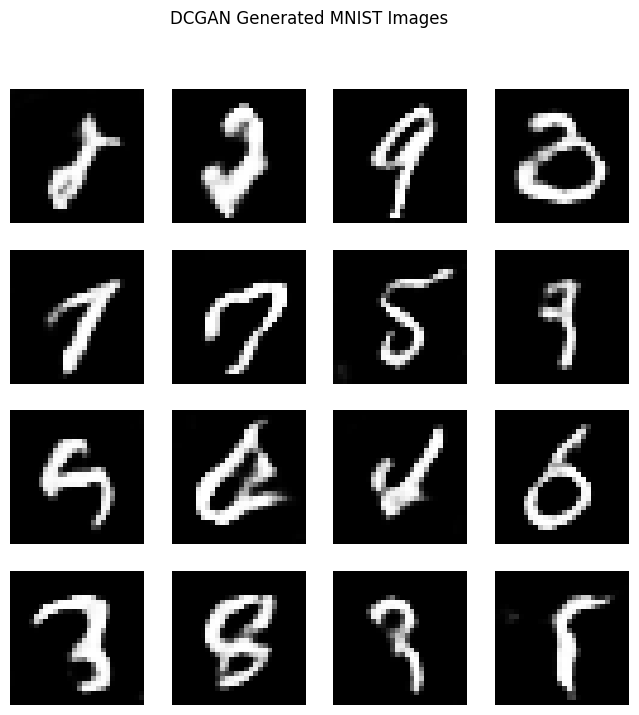

In [16]:
# Display generated images

plt.figure(figsize=(8, 8))

for i in range(num_images):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        generated_images[i, :, :, 0] * 0.5 + 0.5,
        cmap="gray"
    )
    plt.axis("off")

plt.suptitle("DCGAN Generated MNIST Images")
plt.show()

Step 14 — Plot GAN Training Loss

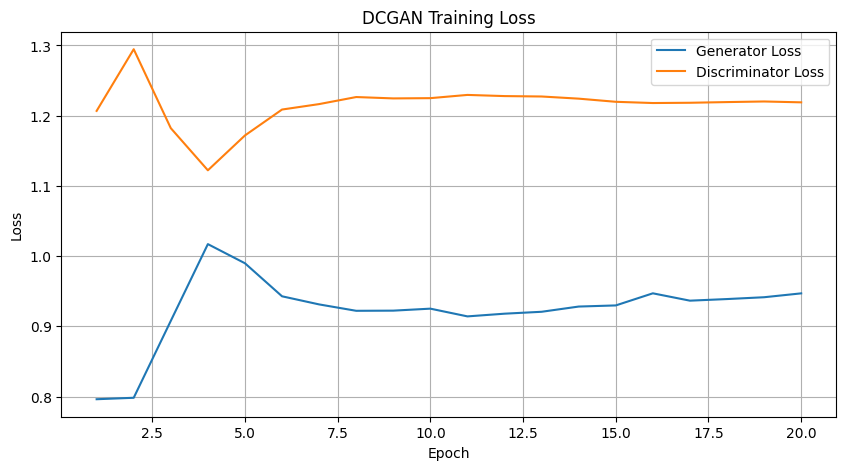

In [17]:
# Plot GAN training losses

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, EPOCHS + 1),
    generator_losses,
    label="Generator Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    discriminator_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.grid(True)

plt.show()

Step 15 — Save the Generated Images

In [18]:
# Create folder for generated images

os.makedirs("generated_images", exist_ok=True)

# Save generated images
for i in range(num_images):
    image = generated_images[i, :, :, 0] * 0.5 + 0.5

    plt.imsave(
        f"generated_images/generated_{i+1}.png",
        image.numpy(),
        cmap="gray"
    )

print("Generated images saved successfully!")

Generated images saved successfully!


In [19]:
# Display saved image files

print(os.listdir("generated_images"))

['generated_6.png', 'generated_3.png', 'generated_13.png', 'generated_12.png', 'generated_5.png', 'generated_7.png', 'generated_11.png', 'generated_10.png', 'generated_15.png', 'generated_2.png', 'generated_14.png', 'generated_8.png', 'generated_4.png', 'generated_16.png', 'generated_9.png', 'generated_1.png']


Step 16 — Start Part B: Build the Baseline CNN Model

In [20]:
# Part B: Model Optimization
# Build Baseline CNN Model

baseline_model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),

    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Step 17 — Prepare MNIST Data for the CNN

In [21]:
# Prepare MNIST data for CNN

x_train_cnn = x_train.astype("float32")
x_test_cnn = x_test.astype("float32")

# Convert pixel values from 0-255 to 0-1
x_train_cnn = (x_train_cnn + 1) / 2
x_test_cnn = x_test_cnn / 255.0

# Make sure training images have channel dimension
if len(x_train_cnn.shape) == 3:
    x_train_cnn = np.expand_dims(x_train_cnn, axis=-1)

if len(x_test_cnn.shape) == 3:
    x_test_cnn = np.expand_dims(x_test_cnn, axis=-1)

print("Training data shape:", x_train_cnn.shape)
print("Testing data shape:", x_test_cnn.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


Step 18 — Train the Baseline CNN Model

In [22]:
# Train the Baseline CNN Model

baseline_history = baseline_model.fit(
    x_train_cnn,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

print("Baseline CNN training completed!")

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 110ms/step - accuracy: 0.9344 - loss: 0.2314 - val_accuracy: 0.9828 - val_loss: 0.0615
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 77s 99ms/step - accuracy: 0.9803 - loss: 0.0634 - val_accuracy: 0.9875 - val_loss: 0.0450
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 99ms/step - accuracy: 0.9858 - loss: 0.0452 - val_accuracy: 0.9877 - val_loss: 0.0450
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 82s 99ms/step - accuracy: 0.9898 - loss: 0.0331 - val_accuracy: 0.9887 - val_loss: 0.0398
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 83s 101ms/step - accuracy: 0.9921 - loss: 0.0255 - val_accuracy: 0.9900 - val_loss: 0.0409
Baseline CNN training completed!


Step 19 — Evaluate the Baseline CNN

In [28]:
# Step 19 — Evaluate Baseline CNN

baseline_loss, baseline_accuracy = baseline_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=0
)

print("Baseline Test Loss:", baseline_loss)
print("Baseline Test Accuracy:", baseline_accuracy)
print("Baseline Test Accuracy (%):", baseline_accuracy * 100)

Baseline Test Loss: 0.03257865458726883
Baseline Test Accuracy: 0.9894000291824341
Baseline Test Accuracy (%): 98.94000291824341


Step 20 — Measure Baseline Model Size

In [29]:
# Step 20 — Measure Baseline Model Size

baseline_params = baseline_model.count_params()

# Assuming each parameter uses 4 bytes (float32)
baseline_size_mb = (baseline_params * 4) / (1024 ** 2)

print("Baseline Model Parameters:", baseline_params)
print("Baseline Model Size (MB):", baseline_size_mb)

Baseline Model Parameters: 225034
Baseline Model Size (MB): 0.8584365844726562


Step 21 — Apply Model Pruning

In [33]:
!pip install -q tf-keras

In [40]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tensorflow_model_optimization as tfmot

print("TensorFlow:", tf.__version__)
print("TFMOT imported successfully!")

TensorFlow: 2.20.0
TFMOT imported successfully!


In [42]:
# Step 21 — Apply Model Pruning

import tf_keras as tfk
import tensorflow_model_optimization as tfmot

# Recreate baseline model using the legacy tf_keras to ensure tfmot compatibility
legacy_baseline = tfk.Sequential([
    tfk.layers.Input(shape=(28, 28, 1)),
    tfk.layers.Conv2D(32, (3, 3), activation="relu"),
    tfk.layers.MaxPooling2D((2, 2)),
    tfk.layers.Conv2D(64, (3, 3), activation="relu"),
    tfk.layers.MaxPooling2D((2, 2)),
    tfk.layers.Flatten(),
    tfk.layers.Dense(128, activation="relu"),
    tfk.layers.Dense(10, activation="softmax")
])

# Transfer trained weights from Keras 3 model
legacy_baseline.set_weights(baseline_model.get_weights())

pruning_params = {
    "pruning_schedule": tfmot.sparsity.keras.PolynomialDecay(
        initial_sparsity=0.0,
        final_sparsity=0.50,
        begin_step=0,
        end_step=1000
    )
}

# Apply pruning on the legacy-compatible model
pruned_model = tfmot.sparsity.keras.prune_low_magnitude(
    legacy_baseline,
    **pruning_params
)

pruned_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model pruning applied successfully!")

pruned_model.summary()

Model pruning applied successfully!
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 prune_low_magnitude_conv2d  (None, 26, 26, 32)        610       
  (PruneLowMagnitude)                                            
                                                                 
 prune_low_magnitude_max_po  (None, 13, 13, 32)        1         
 oling2d (PruneLowMagnitude                                      
 )                                                               
                                                                 
 prune_low_magnitude_conv2d  (None, 11, 11, 64)        36930     
 _1 (PruneLowMagnitude)                                          
                                                                 
 prune_low_magnitude_max_po  (None, 5, 5, 64)          1         
 oling2d_1 (PruneLowMagnitu                                      
 de)                

Step 22 — Create the Pruned CNN Model

In [43]:
# Step 22 — Create the Pruned CNN Model

pruned_cnn_model = pruned_model

print("Pruned CNN Model created successfully!")

pruned_cnn_model.summary()

Pruned CNN Model created successfully!
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 prune_low_magnitude_conv2d  (None, 26, 26, 32)        610       
  (PruneLowMagnitude)                                            
                                                                 
 prune_low_magnitude_max_po  (None, 13, 13, 32)        1         
 oling2d (PruneLowMagnitude                                      
 )                                                               
                                                                 
 prune_low_magnitude_conv2d  (None, 11, 11, 64)        36930     
 _1 (PruneLowMagnitude)                                          
                                                                 
 prune_low_magnitude_max_po  (None, 5, 5, 64)          1         
 oling2d_1 (PruneLowMagnitu                                      
 de)             

Step 23 — Train the Pruned CNN Model

In [44]:
# Step 23 — Train the Pruned CNN Model

import tensorflow_model_optimization as tfmot

callbacks = [
    tfmot.sparsity.keras.UpdatePruningStep()
]

pruned_history = pruned_cnn_model.fit(
    x_train_cnn,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=callbacks,
    verbose=1
)

print("Pruned CNN Model training completed successfully!")

Epoch 1/10
422/422 [==============================] - 48s 104ms/step - loss: 0.0233 - accuracy: 0.9926 - val_loss: 0.0318 - val_accuracy: 0.9905
Epoch 2/10
422/422 [==============================] - 60s 143ms/step - loss: 0.0165 - accuracy: 0.9951 - val_loss: 0.0349 - val_accuracy: 0.9902
Epoch 3/10
422/422 [==============================] - 47s 112ms/step - loss: 0.0100 - accuracy: 0.9970 - val_loss: 0.0357 - val_accuracy: 0.9913
Epoch 4/10
422/422 [==============================] - 45s 108ms/step - loss: 0.0086 - accuracy: 0.9972 - val_loss: 0.0368 - val_accuracy: 0.9915
Epoch 5/10
422/422 [==============================] - 42s 99ms/step - loss: 0.0061 - accuracy: 0.9980 - val_loss: 0.0386 - val_accuracy: 0.9918
Epoch 6/10
422/422 [==============================] - 43s 102ms/step - loss: 0.0052 - accuracy: 0.9983 - val_loss: 0.0438 - val_accuracy: 0.9907
Epoch 7/10
422/422 [==============================] - 42s 100ms/step - loss: 0.0035 - accuracy: 0.9990 - val_loss: 0.0429 - val_acc

Step 24 — Evaluate the Pruned CNN

In [46]:
# Step 24 — Evaluate the Pruned CNN

pruned_loss, pruned_accuracy = pruned_cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=1
)

print("\nPruned CNN Test Loss:", pruned_loss)
print("Pruned CNN Test Accuracy:", pruned_accuracy)
print("Pruned CNN Test Accuracy (%):", pruned_accuracy * 100)

313/313 [==============================] - 3s 9ms/step - loss: 0.0380 - accuracy: 0.9921

Pruned CNN Test Loss: 0.03801596164703369
Pruned CNN Test Accuracy: 0.9921000003814697
Pruned CNN Test Accuracy (%): 99.21000003814697


Step 25 — Strip Pruning Wrappers and Save the Pruned Model

In [45]:
# Step 25 — Strip Pruning Wrappers and Save the Pruned Model

import tensorflow_model_optimization as tfmot

# Remove pruning wrappers
final_pruned_model = tfmot.sparsity.keras.strip_pruning(
    pruned_cnn_model
)

# Save the final pruned model
final_pruned_model.save("pruned_cnn_model.keras")

print("Pruning wrappers removed successfully!")
print("Final pruned model saved as: pruned_cnn_model.keras")

# Display model summary
final_pruned_model.summary()

Pruning wrappers removed successfully!
Final pruned model saved as: pruned_cnn_model.keras
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2  (None, 13, 13, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 1600)              0         
                               

Step 26 — Apply Quantization

In [47]:
# Step 26 — Apply Quantization

import tensorflow_model_optimization as tfmot

# Apply quantization to the final pruned model
quantized_model = tfmot.quantization.keras.quantize_model(
    final_pruned_model
)

# Compile the quantized model
quantized_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Quantization applied successfully!")

quantized_model.summary()

Quantization applied successfully!
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 quantize_layer (QuantizeLa  (None, 28, 28, 1)         3         
 yer)                                                            
                                                                 
 quant_conv2d (QuantizeWrap  (None, 26, 26, 32)        387       
 perV2)                                                          
                                                                 
 quant_max_pooling2d (Quant  (None, 13, 13, 32)        1         
 izeWrapperV2)                                                   
                                                                 
 quant_conv2d_1 (QuantizeWr  (None, 11, 11, 64)        18627     
 apperV2)                                                        
                                                                 
 quant_max_pooling2d_